In [30]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import joblib


In [31]:
df = pd.read_csv("../dataset/2013 dataset/creditcard.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [32]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  

In [33]:
print("Missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
0

Duplicate rows:
1081


In [34]:
print("Class Distribution:")
print(df["Class"].value_counts())

print("\nClass Percentage:")
print(df["Class"].value_counts(normalize=True) * 100)

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class Percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [35]:
duplicates = df[df.duplicated(keep=False)]

print("Total duplicate rows:", len(duplicates))

display(
    duplicates
    .sort_values(by=["Class"])
    .head(20)
)

Total duplicate rows: 1854


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
1382,1074.0,-2.248488,-0.195670,0.026949,-0.525780,-0.238759,-0.033359,0.162196,0.928520,-0.424215,...,-0.032208,-0.745757,-0.243193,-0.821633,-0.030402,0.335838,-0.286998,-0.243768,158.00,0
1383,1074.0,-2.445204,-0.505494,0.164511,-0.449658,0.460784,-0.509035,-0.490478,1.060597,-0.385591,...,0.060361,-0.802101,-0.299229,-0.831608,-0.055518,0.315454,-0.467257,-0.167591,1.00,0
1384,1074.0,-2.445204,-0.505494,0.164511,-0.449658,0.460784,-0.509035,-0.490478,1.060597,-0.385591,...,0.060361,-0.802101,-0.299229,-0.831608,-0.055518,0.315454,-0.467257,-0.167591,1.00,0
1683,1308.0,-1.322313,0.863591,1.844234,1.089375,0.771005,0.152191,1.491514,-0.917308,0.765538,...,-0.340315,0.315702,-0.133591,0.107112,0.246560,-0.309290,-0.510963,-0.349976,25.30,0
1684,1308.0,-1.322313,0.863591,1.844234,1.089375,0.771005,0.152191,1.491514,-0.917308,0.765538,...,-0.340315,0.315702,-0.133591,0.107112,0.246560,-0.309290,-0.510963,-0.349976,25.30,0
1685,1308.0,-1.379848,0.536720,2.647870,1.408111,0.126442,0.986525,0.960251,-0.629717,1.729173,...,-0.666874,-0.343574,0.022138,0.093532,0.011293,-0.503395,-0.438189,-0.346731,43.80,0
1686,1308.0,-1.379848,0.536720,2.647870,1.408111,0.126442,0.986525,0.960251,-0.629717,1.729173,...,-0.666874,-0.343574,0.022138,0.093532,0.011293,-0.503395,-0.438189,-0.346731,43.80,0
2003,1548.0,-1.559446,1.425546,0.812589,-1.129381,0.507528,0.183507,0.654304,0.088059,0.480018,...,-0.283995,-0.413642,-0.234995,-0.789509,0.324851,0.419737,0.329608,0.351346,5.00,0
2004,1548.0,-1.559446,1.425546,0.812589,-1.129381,0.507528,0.183507,0.654304,0.088059,0.480018,...,-0.283995,-0.413642,-0.234995,-0.789509,0.324851,0.419737,0.329608,0.351346,5.00,0


In [36]:
print("Duplicate class distribution:")
print(duplicates["Class"].value_counts())

Duplicate class distribution:
Class
0    1822
1      32
Name: count, dtype: int64


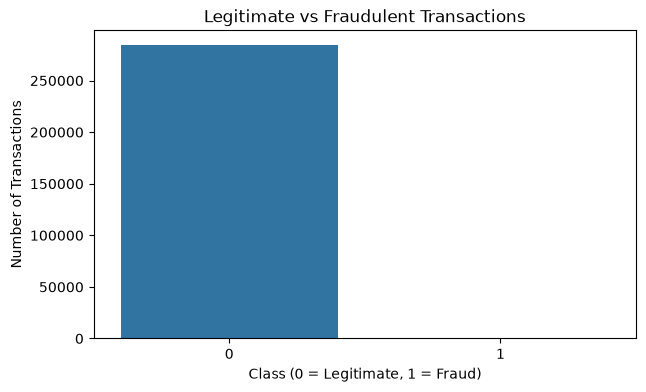

In [37]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="Class")

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

In [38]:
duplicates = df[df.duplicated(keep=False)]

print("Total duplicate rows:", len(duplicates))

print("\nDuplicate class distribution:")
print(duplicates["Class"].value_counts())

Total duplicate rows: 1854

Duplicate class distribution:
Class
0    1822
1      32
Name: count, dtype: int64


In [39]:
df_clean = df.drop_duplicates().copy()

print("Original shape:", df.shape)
print("After removing duplicates:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

Original shape: (284807, 31)
After removing duplicates: (283726, 31)
Rows removed: 1081


In [40]:
X = df_clean.drop("Class", axis=1)
y = df_clean["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

Features shape: (283726, 30)
Target shape: (283726,)

Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training data: (226980, 30)
Testing data: (56746, 30)

Training class distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing class distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [42]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train["Amount"] = scaler.fit_transform(X_train[["Amount"]])
X_test["Amount"] = scaler.transform(X_test[["Amount"]])

print("Amount scaled successfully!")

Amount scaled successfully!


In [43]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=100,
    contamination=0.0017,
    random_state=42,
    n_jobs=-1
)

print("Training Isolation Forest...")

model.fit(X_train[y_train == 0])

print("✅ Model trained successfully!")

Training Isolation Forest...
✅ Model trained successfully!


In [44]:
y_pred_raw = model.predict(X_test)

print("Raw predictions:")
print(pd.Series(y_pred_raw).value_counts())

Raw predictions:
 1    56617
-1      129
Name: count, dtype: int64


In [45]:
y_pred = np.where(y_pred_raw == -1, 1, 0)

print("Converted predictions:")
print(pd.Series(y_pred).value_counts())

Converted predictions:
0    56617
1      129
Name: count, dtype: int64


In [46]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nPrecision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Confusion Matrix:
[[56538   113]
 [   79    16]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.12      0.17      0.14        95

    accuracy                           1.00     56746
   macro avg       0.56      0.58      0.57     56746
weighted avg       1.00      1.00      1.00     56746


Precision: 0.12403100775193798
Recall: 0.16842105263157894
F1 Score: 0.14285714285714285


In [47]:
contamination_values = [0.001, 0.0017, 0.002, 0.003, 0.005]

results = []

for contamination in contamination_values:

    temp_model = IsolationForest(
        n_estimators=100,
        contamination=contamination,
        random_state=42,
        n_jobs=-1
    )

    temp_model.fit(X_train[y_train == 0])

    temp_pred_raw = temp_model.predict(X_test)
    temp_pred = np.where(temp_pred_raw == -1, 1, 0)

    precision = precision_score(y_test, temp_pred, zero_division=0)
    recall = recall_score(y_test, temp_pred, zero_division=0)
    f1 = f1_score(y_test, temp_pred, zero_division=0)

    results.append({
        "Contamination": contamination,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

results_df = pd.DataFrame(results)

display(results_df)

,Contamination,Precision,Recall,F1
0,0.0010,0.106667,0.084211,0.094118
1,0.0017,0.124031,0.168421,0.142857
2,0.0020,0.111111,0.168421,0.133891
3,0.0030,0.113636,0.263158,0.158730
4,0.0050,0.101156,0.368421,0.158730


In [48]:
# Train the model with contamination = 0.005

model_005 = IsolationForest(
    n_estimators=100,
    contamination=0.005,
    random_state=42,
    n_jobs=-1
)

model_005.fit(X_train[y_train == 0])

# Get anomaly scores
scores = model_005.decision_function(X_test)

print("Minimum score:", scores.min())
print("Maximum score:", scores.max())
print("Mean score:", scores.mean())

Minimum score: -0.16196206051990225
Maximum score: 0.25868465339434343
Mean score: 0.19735971303024333


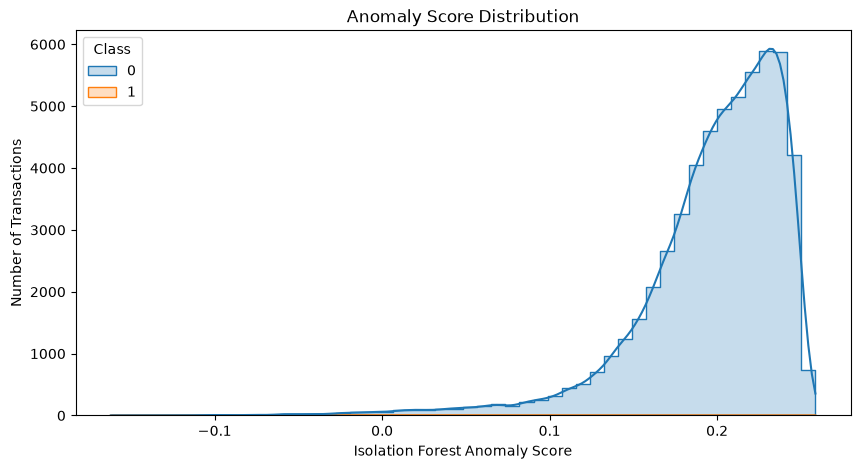

In [49]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=pd.DataFrame({
        "Anomaly Score": scores,
        "Class": y_test.values
    }),
    x="Anomaly Score",
    hue="Class",
    bins=50,
    kde=True,
    element="step"
)

plt.title("Anomaly Score Distribution")
plt.xlabel("Isolation Forest Anomaly Score")
plt.ylabel("Number of Transactions")

plt.show()

In [51]:
score_df = pd.DataFrame({
    "Anomaly_Score": scores,
    "Class": y_test.values
})

print(score_df.head())
print("Shape:", score_df.shape)

   Anomaly_Score  Class
0       0.241857      0
1       0.227196      0
2       0.173526      0
3       0.220569      0
4       0.229840      0
Shape: (56746, 2)


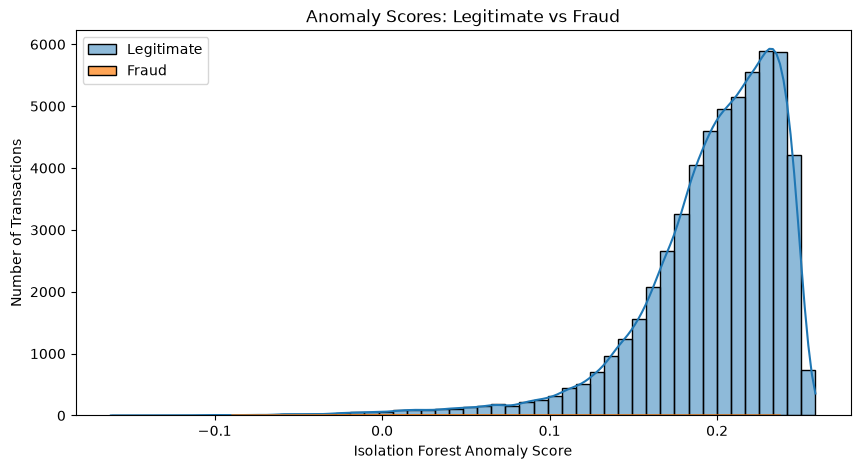

In [52]:
plt.figure(figsize=(10, 5))

sns.histplot(
    score_df.loc[score_df["Class"] == 0, "Anomaly_Score"],
    bins=50,
    kde=True,
    label="Legitimate",
    alpha=0.5
)

sns.histplot(
    score_df.loc[score_df["Class"] == 1, "Anomaly_Score"],
    bins=30,
    kde=True,
    label="Fraud",
    alpha=0.7
)

plt.title("Anomaly Scores: Legitimate vs Fraud")
plt.xlabel("Isolation Forest Anomaly Score")
plt.ylabel("Number of Transactions")
plt.legend()

plt.show()

In [53]:
print("Average anomaly score — Legitimate:")
print(score_df.loc[score_df["Class"] == 0, "Anomaly_Score"].mean())

print("\nAverage anomaly score — Fraud:")
print(score_df.loc[score_df["Class"] == 1, "Anomaly_Score"].mean())

Average anomaly score — Legitimate:
0.1976185251056837

Average anomaly score — Fraud:
0.04302326160103328


In [54]:
fraud_mean = score_df.loc[
    score_df["Class"] == 1,
    "Anomaly_Score"
].mean()

print("Average anomaly score — Fraud:", fraud_mean)

Average anomaly score — Fraud: 0.04302326160103328


In [55]:
from sklearn.metrics import roc_auc_score, average_precision_score

fraud_score = -scores

roc_auc = roc_auc_score(y_test, fraud_score)
pr_auc = average_precision_score(y_test, fraud_score)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.9292718389325593
PR-AUC: 0.0703731495795467


In [56]:
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Sub-training:", X_subtrain.shape)
print("Validation:", X_val.shape)

print("\nSub-training fraud:", y_subtrain.sum())
print("Validation fraud:", y_val.sum())

Sub-training: (181584, 30)
Validation: (45396, 30)

Sub-training fraud: 302
Validation fraud: 76


In [57]:
from sklearn.ensemble import IsolationForest

val_model = IsolationForest(
    n_estimators=100,
    contamination=0.005,
    random_state=42,
    n_jobs=-1
)

print("Training validation model...")

val_model.fit(X_subtrain[y_subtrain == 0])

print("✅ Validation model trained!")

Training validation model...
✅ Validation model trained!


In [58]:
val_scores = val_model.decision_function(X_val)

print("Minimum score:", val_scores.min())
print("Maximum score:", val_scores.max())
print("Mean score:", val_scores.mean())

Minimum score: -0.1520096953573541
Maximum score: 0.2536337991497489
Mean score: 0.19122146256742395


In [59]:
from sklearn.metrics import precision_score, recall_score, f1_score

fraud_score_val = -val_scores

thresholds = np.linspace(
    fraud_score_val.min(),
    fraud_score_val.max(),
    200
)

threshold_results = []

for threshold in thresholds:

    val_pred = (fraud_score_val >= threshold).astype(int)

    precision = precision_score(
        y_val,
        val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        val_pred,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values(
        "F1",
        ascending=False
    ).head(10)
)

,Threshold,Precision,Recall,F1
128,0.007283,0.101523,0.263158,0.146520
141,0.033782,0.133333,0.157895,0.144578
137,0.025628,0.118644,0.184211,0.144330
130,0.011359,0.102273,0.236842,0.142857
140,0.031744,0.129032,0.157895,0.142012
105,-0.039601,0.080420,0.605263,0.141975
127,0.005244,0.096154,0.263158,0.140845
134,0.019513,0.109489,0.197368,0.140845
123,-0.002909,0.091270,0.302632,0.140244
106,-0.037562,0.079279,0.578947,0.139461


In [60]:
selected_threshold = 0.007283

test_fraud_score = -model_005.decision_function(X_test)

y_test_tuned = (
    test_fraud_score >= selected_threshold
).astype(int)

print("Tuned Test Results")
print("------------------")

print("Precision:",
      precision_score(y_test, y_test_tuned, zero_division=0))

print("Recall:",
      recall_score(y_test, y_test_tuned, zero_division=0))

print("F1:",
      f1_score(y_test, y_test_tuned, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_tuned))

Tuned Test Results
------------------
Precision: 0.11148648648648649
Recall: 0.3473684210526316
F1: 0.16879795396419436

Confusion Matrix:
[[56388   263]
 [   62    33]]


In [61]:
X_lof_train = X_subtrain[y_subtrain == 0].sample(
    n=50000,
    random_state=42
)

print("LOF training data:", X_lof_train.shape)

LOF training data: (50000, 30)


In [62]:
from sklearn.neighbors import LocalOutlierFactor

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.005,
    novelty=True,
    n_jobs=-1
)

print("Training LOF...")

lof_model.fit(X_lof_train)

print("✅ LOF trained successfully!")

Training LOF...
✅ LOF trained successfully!


In [63]:
lof_pred_raw = lof_model.predict(X_val)

print("Raw LOF predictions:")
print(pd.Series(lof_pred_raw).value_counts())

c:\HCL project\Credit-Card Fraud detection\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Raw LOF predictions:
 1    45166
-1      230
Name: count, dtype: int64


In [64]:
lof_pred = np.where(lof_pred_raw == -1, 1, 0)

print("LOF Validation Results")
print("----------------------")

print("Precision:",
      precision_score(y_val, lof_pred, zero_division=0))

print("Recall:",
      recall_score(y_val, lof_pred, zero_division=0))

print("F1:",
      f1_score(y_val, lof_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, lof_pred))

LOF Validation Results
----------------------
Precision: 0.02608695652173913
Recall: 0.07894736842105263
F1: 0.0392156862745098

Confusion Matrix:
[[45096   224]
 [   70     6]]


In [65]:
neighbor_values = [10, 20, 35, 50]

lof_results = []

for n in neighbor_values:

    temp_lof = LocalOutlierFactor(
        n_neighbors=n,
        contamination=0.005,
        novelty=True,
        n_jobs=-1
    )

    temp_lof.fit(X_lof_train)

    pred_raw = temp_lof.predict(X_val)
    pred = np.where(pred_raw == -1, 1, 0)

    precision = precision_score(y_val, pred, zero_division=0)
    recall = recall_score(y_val, pred, zero_division=0)
    f1 = f1_score(y_val, pred, zero_division=0)

    lof_results.append({
        "n_neighbors": n,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

lof_results_df = pd.DataFrame(lof_results)

display(lof_results_df)

c:\HCL project\Credit-Card Fraud detection\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
c:\HCL project\Credit-Card Fraud detection\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
c:\HCL project\Credit-Card Fraud detection\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
c:\HCL project\Credit-Card Fraud detection\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


,n_neighbors,Precision,Recall,F1
0,10,0.072727,0.210526,0.108108
1,20,0.026087,0.078947,0.039216
2,35,0.009662,0.026316,0.014134
3,50,0.013333,0.039474,0.019934


In [66]:
from sklearn.svm import OneClassSVM

X_svm_train = X_subtrain[y_subtrain == 0].sample(
    n=20000,
    random_state=42
)

print("One-Class SVM training data:", X_svm_train.shape)

One-Class SVM training data: (20000, 30)


In [67]:
from sklearn.svm import OneClassSVM

svm_model = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.005
)

print("Training One-Class SVM...")

svm_model.fit(X_svm_train)

print("✅ One-Class SVM trained successfully!")

Training One-Class SVM...
✅ One-Class SVM trained successfully!


In [68]:
svm_pred_raw = svm_model.predict(X_val)

print("Raw One-Class SVM predictions:")
print(pd.Series(svm_pred_raw).value_counts())

Raw One-Class SVM predictions:
 1    44970
-1      426
Name: count, dtype: int64


In [69]:
svm_pred = np.where(svm_pred_raw == -1, 1, 0)

print("One-Class SVM Validation Results")
print("--------------------------------")

print("Precision:",
      precision_score(y_val, svm_pred, zero_division=0))

print("Recall:",
      recall_score(y_val, svm_pred, zero_division=0))

print("F1:",
      f1_score(y_val, svm_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, svm_pred))

One-Class SVM Validation Results
--------------------------------
Precision: 0.002347417840375587
Recall: 0.013157894736842105
F1: 0.00398406374501992

Confusion Matrix:
[[44895   425]
 [   75     1]]


In [70]:
comparison = pd.DataFrame({
    "Model": [
        "Isolation Forest",
        "LOF (n_neighbors=10)",
        "One-Class SVM"
    ],
    "Precision": [
        0.101523,
        0.072727,
        0.002347
    ],
    "Recall": [
        0.263158,
        0.210526,
        0.013158
    ],
    "F1 Score": [
        0.146520,
        0.108108,
        0.003984
    ]
})

display(comparison)

,Model,Precision,Recall,F1 Score
0,Isolation Forest,0.101523,0.263158,0.146520
1,LOF (n_neighbors=10),0.072727,0.210526,0.108108
2,One-Class SVM,0.002347,0.013158,0.003984


In [71]:
from sklearn.ensemble import IsolationForest

final_model = IsolationForest(
    n_estimators=200,
    contamination=0.005,
    random_state=42,
    n_jobs=-1
)

print("Training final Isolation Forest...")

final_model.fit(X_train[y_train == 0])

print("✅ Final model trained!")

Training final Isolation Forest...
✅ Final model trained!


In [72]:
import joblib
import os

# Make sure the models folder exists
os.makedirs("../models", exist_ok=True)

# Save final model
joblib.dump(
    final_model,
    "../models/isolation_forest.pkl"
)

# Save the scaler used for Amount
joblib.dump(
    scaler,
    "../models/scaler.pkl"
)

print("✅ Model saved:")
print("../models/isolation_forest.pkl")

print("\n✅ Scaler saved:")
print("../models/scaler.pkl")


✅ Model saved:
../models/isolation_forest.pkl

✅ Scaler saved:
../models/scaler.pkl


In [73]:
# ============================================================
# FINAL CLEAN TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Start from cleaned dataset
X = df_clean.drop("Class", axis=1)
y = df_clean["Class"]

# First split: 80% development, 20% untouched test
X_dev, X_test_final, y_dev, y_test_final = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: development -> 60% train, 20% validation
X_train_final, X_val_final, y_train_final, y_val_final = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("Final dataset split:")
print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Test:", X_test_final.shape)

print("\nFraud counts:")
print("Training fraud:", y_train_final.sum())
print("Validation fraud:", y_val_final.sum())
print("Test fraud:", y_test_final.sum())


Final dataset split:
Training: (170235, 30)
Validation: (56745, 30)
Test: (56746, 30)

Fraud counts:
Training fraud: 284
Validation fraud: 94
Test fraud: 95


In [74]:
# ============================================================
# FINAL SCALING
# ============================================================

scaler_final = StandardScaler()

X_train_final = X_train_final.copy()
X_val_final = X_val_final.copy()
X_test_final = X_test_final.copy()

# Fit ONLY on training data
X_train_final["Amount"] = scaler_final.fit_transform(
    X_train_final[["Amount"]]
)

# Apply same scaler
X_val_final["Amount"] = scaler_final.transform(
    X_val_final[["Amount"]]
)

X_test_final["Amount"] = scaler_final.transform(
    X_test_final[["Amount"]]
)

print("Scaling completed successfully.")

Scaling completed successfully.


In [75]:
from sklearn.ensemble import IsolationForest

final_model_clean = IsolationForest(
    n_estimators=200,
    contamination=0.005,
    random_state=42,
    n_jobs=-1
)

# Train ONLY on legitimate transactions
final_model_clean.fit(
    X_train_final[y_train_final == 0]
)

print("Final clean Isolation Forest trained! ✅")

Final clean Isolation Forest trained! ✅


In [76]:
# ============================================================
# THRESHOLD TUNING — VALIDATION SET ONLY
# ============================================================

from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

# Get anomaly scores
val_scores_clean = final_model_clean.decision_function(X_val_final)

# Convert to fraud scores
# Higher score = more likely to be fraud
fraud_score_val_clean = -val_scores_clean

# Try different thresholds
thresholds = np.linspace(
    fraud_score_val_clean.min(),
    fraud_score_val_clean.max(),
    200
)

results = []

for threshold in thresholds:
    y_pred = (fraud_score_val_clean >= threshold).astype(int)

    precision = precision_score(
        y_val_final, y_pred, zero_division=0
    )
    recall = recall_score(
        y_val_final, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_val_final, y_pred, zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_results = pd.DataFrame(results)

# Find threshold with highest validation F1
best_result = threshold_results.loc[
    threshold_results["F1"].idxmax()
]

print("Best validation threshold:")
print(best_result)

Best validation threshold:
Threshold    0.036042
Precision    0.192308
Recall       0.265957
F1           0.223214
Name: 150, dtype: float64


In [77]:
# ============================================================
# FINAL EVALUATION — UNTOUCHED TEST SET
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# Locked threshold from validation
selected_threshold = best_result["Threshold"]

# Get test anomaly scores
test_scores_clean = final_model_clean.decision_function(X_test_final)

# Convert to fraud scores
fraud_score_test_clean = -test_scores_clean

# Apply LOCKED threshold
y_pred_test_final = (
    fraud_score_test_clean >= selected_threshold
).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_test_final, y_pred_test_final)
precision = precision_score(
    y_test_final, y_pred_test_final, zero_division=0
)
recall = recall_score(
    y_test_final, y_pred_test_final, zero_division=0
)
f1 = f1_score(
    y_test_final, y_pred_test_final, zero_division=0
)

roc_auc = roc_auc_score(
    y_test_final, fraud_score_test_clean
)

pr_auc = average_precision_score(
    y_test_final, fraud_score_test_clean
)

print("========== FINAL TEST RESULTS ==========")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_final, y_pred_test_final))

print("\nClassification Report:")
print(classification_report(
    y_test_final,
    y_pred_test_final,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

========== FINAL TEST RESULTS ==========
Accuracy  : 0.9968
Precision : 0.1818
Recall    : 0.2526
F1 Score  : 0.2115
ROC-AUC   : 0.9407
PR-AUC    : 0.0913

Confusion Matrix:
[[56543   108]
 [   71    24]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.18      0.25      0.21        95

    accuracy                           1.00     56746
   macro avg       0.59      0.63      0.60     56746
weighted avg       1.00      1.00      1.00     56746



In [78]:
# ============================================================
# SAVE FINAL MODEL ARTIFACTS
# ============================================================

import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_model_clean,
    "../models/final_isolation_forest.pkl"
)

joblib.dump(
    scaler_final,
    "../models/final_scaler.pkl"
)

joblib.dump(
    selected_threshold,
    "../models/fraud_threshold.pkl"
)

print("Final model saved! ✅")
print("Final scaler saved! ✅")
print("Fraud threshold saved! ✅")

Final model saved! ✅
Final scaler saved! ✅
Fraud threshold saved! ✅


In [80]:
import mysql.connector

connection = mysql.connector.connect(
    host="127.0.0.1",
    port=3307,
    user="root",
    password="Fraud@2026",
    database="credit_card_fraud"
)

print("MySQL connection successful! ✅")

cursor = connection.cursor()
cursor.execute("SELECT DATABASE();")

print("Connected database:", cursor.fetchone()[0])

MySQL connection successful! ✅
Connected database: credit_card_fraud


In [82]:
# Test MySQL insertion with 5 transactions

test_data = df_clean.head(5)

insert_query = """
INSERT INTO transactions (
    Time,
    V1, V2, V3, V4, V5, V6, V7, V8, V9, V10,
    V11, V12, V13, V14, V15, V16, V17, V18, V19, V20,
    V21, V22, V23, V24, V25, V26, V27, V28,
    Amount,
    actual_class
)
VALUES (
    %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s,
    %s, %s, %s, %s, %s, %s, %s, %s, %s, %s,
    %s, %s, %s, %s, %s, %s, %s, %s, %s, %s
)
"""

cursor = connection.cursor()

for _, row in test_data.iterrows():
    values = tuple(row[col] for col in df_clean.columns)
    cursor.execute(insert_query, values)

connection.commit()

print("5 test transactions inserted successfully! ✅")
cursor.execute("SELECT COUNT(*) FROM transactions;")

print("Rows in MySQL:", cursor.fetchone()[0])

5 test transactions inserted successfully! ✅
Rows in MySQL: 10


In [83]:
connection.close()
print("Python MySQL connection closed.")

Python MySQL connection closed.


In [85]:
# ============================================================
# LOAD FINAL FRAUD DETECTION RESULTS INTO MYSQL
# ============================================================

import mysql.connector
import numpy as np

# ------------------------------------------------------------
# 1. Prepare complete dataset
# ------------------------------------------------------------

X_all = df_clean.drop("Class", axis=1).copy()
y_all = df_clean["Class"].copy()

# Scale Amount using the scaler fitted ONLY on training data
X_all["Amount"] = scaler_final.transform(
    X_all[["Amount"]]
)

# ------------------------------------------------------------
# 2. Generate anomaly scores
# ------------------------------------------------------------

print("Generating anomaly scores...")

decision_scores = final_model_clean.decision_function(X_all)

# Higher = more likely to be fraud
anomaly_scores = -decision_scores

# Use the threshold selected from validation
predicted_fraud = (
    anomaly_scores >= selected_threshold
).astype(int)

print("Predictions generated! ✅")
print("Total transactions:", len(X_all))
print("Predicted fraud:", predicted_fraud.sum())

# ------------------------------------------------------------
# 3. Connect to MySQL
# ------------------------------------------------------------

connection = mysql.connector.connect(
    host="127.0.0.1",
    port=3307,
    user="root",
    password="Fraud@2026",
    database="credit_card_fraud"
)

cursor = connection.cursor()

print("Connected to MySQL! ✅")

# ------------------------------------------------------------
# 4. SQL INSERT query
# ------------------------------------------------------------

insert_query = """
INSERT INTO transactions (
    Time,
    V1, V2, V3, V4, V5, V6, V7, V8, V9, V10,
    V11, V12, V13, V14, V15, V16, V17, V18, V19, V20,
    V21, V22, V23, V24, V25, V26, V27, V28,
    Amount,
    actual_class,
    anomaly_score,
    predicted_fraud
)
VALUES (
    %s, %s, %s, %s, %s, %s, %s, %s, %s, %s, %s,
    %s, %s, %s, %s, %s, %s, %s, %s, %s, %s,
    %s, %s, %s, %s, %s, %s, %s, %s, %s, %s,
    %s, %s
)
"""

# ------------------------------------------------------------
# 5. Prepare rows
# ------------------------------------------------------------

data_to_insert = []

for i in range(len(X_all)):

    row = X_all.iloc[i]

    values = (
        row["Time"],
        *[row[f"V{j}"] for j in range(1, 29)],
        df_clean.iloc[i]["Amount"],
        int(y_all.iloc[i]),
        float(anomaly_scores[i]),
        int(predicted_fraud[i])
    )

    data_to_insert.append(values)

# ------------------------------------------------------------
# 6. Batch insertion
# ------------------------------------------------------------

batch_size = 5000
total_rows = len(data_to_insert)

print(f"Starting insertion of {total_rows:,} rows...")

for start in range(0, total_rows, batch_size):

    batch = data_to_insert[start:start + batch_size]

    cursor.executemany(insert_query, batch)
    connection.commit()

    inserted = min(start + batch_size, total_rows)

    print(f"Inserted {inserted:,} / {total_rows:,}")

print("\n🎉 All transactions inserted successfully!")

cursor.close()
connection.close()

Generating anomaly scores...
Predictions generated! ✅
Total transactions: 283726
Predicted fraud: 674
Connected to MySQL! ✅
Starting insertion of 283,726 rows...
Inserted 5,000 / 283,726
Inserted 10,000 / 283,726
Inserted 15,000 / 283,726
Inserted 20,000 / 283,726
Inserted 25,000 / 283,726
Inserted 30,000 / 283,726
Inserted 35,000 / 283,726
Inserted 40,000 / 283,726
Inserted 45,000 / 283,726
Inserted 50,000 / 283,726
Inserted 55,000 / 283,726
Inserted 60,000 / 283,726
Inserted 65,000 / 283,726
Inserted 70,000 / 283,726
Inserted 75,000 / 283,726
Inserted 80,000 / 283,726
Inserted 85,000 / 283,726
Inserted 90,000 / 283,726
Inserted 95,000 / 283,726
Inserted 100,000 / 283,726
Inserted 105,000 / 283,726
Inserted 110,000 / 283,726
Inserted 115,000 / 283,726
Inserted 120,000 / 283,726
Inserted 125,000 / 283,726
Inserted 130,000 / 283,726
Inserted 135,000 / 283,726
Inserted 140,000 / 283,726
Inserted 145,000 / 283,726
Inserted 150,000 / 283,726
Inserted 155,000 / 283,726
Inserted 160,000 / 28